
# 09 — Resultados y recomendaciones de inversión

## Objetivo

Consolidar los resultados del análisis de propiedades inmobiliarias en CABA para identificar y priorizar oportunidades potenciales de inversión mediante flipping.

A partir del modelo económico desarrollado en la notebook 07 y de la evaluación de hipótesis de la notebook 08, se busca transformar los resultados analíticos en información útil para la toma de decisiones.

## Preguntas de negocio

1. ¿Cuántas oportunidades de inversión se identificaron?
2. ¿Qué propiedades presentan mayor potencial de rentabilidad?
3. ¿Qué características tienen las oportunidades mejor posicionadas?
4. ¿Qué riesgos deben considerarse antes de invertir?
5. ¿Qué propiedades deberían priorizarse para una evaluación más detallada?

## Metodología

Se utilizará el archivo `flipping_ranking_priorizado.csv`, generado en la notebook 07.

El análisis incluirá:

- Caracterización de las oportunidades identificadas.
- Comparación de rentabilidad y riesgo.
- Identificación de las propiedades más atractivas.
- Priorización de oportunidades para su revisión.
- Recomendaciones finales y limitaciones del modelo.

Los resultados representan una preselección basada en datos y supuestos económicos, no recomendaciones definitivas de compra.


In [3]:

import pandas as pd

# Cargar el ranking generado en la notebook 07
df_ranking = pd.read_csv(
    "data/processed/flipping_ranking_priorizado.csv"
)

print("Cantidad total de oportunidades:", len(df_ranking))

print("\nDimensiones del dataset:")
print(df_ranking.shape)

print("\nColumnas disponibles:")
print(df_ranking.columns.tolist())

print("\nDistribución por prioridad:")
display(
    df_ranking["Prioridad_Analisis"]
    .value_counts()
    .rename_axis("Prioridad")
    .reset_index(name="Cantidad")
)

print("\nPrimeras 5 propiedades:")
display(df_ranking.head())


Cantidad total de oportunidades: 46

Dimensiones del dataset:
(46, 131)

Columnas disponibles:
['Ranking', 'ID', 'ID_Entidad', 'Operacion', 'Tipo_Propiedad', 'Titulo', 'Descripcion', 'Fecha_Publicacion', 'Antiguedad', 'Apto_Credito', 'Amenities', 'Moneda', 'Precio_Valor', 'Moneda_Expensas', 'Expensas', 'Precio_m2_Total', 'Precio_m2_Cubierto', 'Ambientes', 'Dormitorios', 'Baños', 'Superficie_Total_m2', 'Superficie_Cubierta_m2', 'Direccion', 'Barrio', 'Ubicacion', 'Latitud', 'Longitud', 'Estado_Publicacion', 'ID_Interno', 'Link', 'Tipo_Propiedad_Original', 'Ambientes_Titulo', 'Flag_Ambientes_Dudoso', 'Flag_Dormitorios_Inconsistente', 'Flag_Posible_Republicacion', 'Expensas_Informadas', 'Antiguedad_Informada', 'Amenities_Informadas', 'Flag_Atipico_Bajo', 'Flag_Atipico_Alto', 'Flag_Extremo', 'Flag_Outlier_Multivariado', 'Barrio_Oficial', 'Comuna', 'Flag_Coordenadas_Invalidas', 'Luminoso', 'Vista', 'Silencioso', 'Contrafrente', 'Al_Frente', 'Apto_Profesional', 'Reciclado_Texto', 'A_Refaccio

,Prioridad,Cantidad
0,Prioridad de análisis,24
1,Revisión adicional,22



Primeras 5 propiedades:


,Ranking,ID,ID_Entidad,Operacion,Tipo_Propiedad,Titulo,Descripcion,Fecha_Publicacion,Antiguedad,Apto_Credito,...,ROI_Optimista_pct,Robustez_Economica,Alerta_Uso_No_Residencial,Alerta_Superficie_Alta,Alerta_ROI_Extremo,Alerta_PER_Nivel_4,Cantidad_Alertas,Requiere_Revision,Prioridad_Analisis,Ranking_Priorizado
0,4,612831,5f2f5736-445c-4aba-8add-96570a0cbce1,sale,departamento,Dúplex Piso alto al frente a refaccionar cochera,Gran oportunidad: Dúplex a refaccionar en piso...,NaN,47.0,False,...,77.108438,Rentable en los tres escenarios,False,False,False,False,0,False,Prioridad de análisis,1
1,11,641943,0f44cdbb-e253-48d0-9466-95d543ae8ec6,sale,departamento,venta tres ambientes a reciclar en Boedo,Excelente oportunidad para transformar a tu gu...,NaN,56.0,True,...,53.861689,Rentable en los tres escenarios,False,False,False,False,0,False,Prioridad de análisis,2
2,12,511218,26ce9dfa-3776-4c61-9713-41d29ab223aa,sale,departamento,Depto 152m² 4Amb Dep Belgrano Cabildo Oportunidad,Departamento de 4 ambientes con balcón terraza...,NaN,61.0,True,...,43.664027,Rentable en los tres escenarios,False,False,False,False,0,False,Prioridad de análisis,3
3,13,580233,6cc9e354-2e17-442a-a308-3c164fc14839,sale,departamento,3 AMBIENTES LUMINOSO- A REFACCIONAR - CONSTITU...,Si estás buscando una propiedad con potencial ...,NaN,74.0,False,...,102.198936,Rentable en los tres escenarios,False,False,False,False,0,False,Prioridad de análisis,4
4,14,518133,07635958-df95-4786-8f98-c74d9c60bcd8,sale,departamento,DEPARTAMENTO 2 AMBIENTES PATIO A REFACCIONAR,OPORTUNIDAD\n\n\nEste encantador departamento ...,NaN,46.0,False,...,57.621616,Rentable en los tres escenarios,False,False,False,False,0,False,Prioridad de análisis,5



## 1. Caracterización de las oportunidades prioritarias

De las 46 propiedades que presentan rentabilidad positiva en los tres escenarios económicos, 24 fueron clasificadas como "Prioridad de análisis" y 22 como "Revisión adicional".

En esta sección se analizan las características de las 24 propiedades prioritarias para identificar patrones de ubicación, precio, superficie y rentabilidad.

El objetivo es comprender qué tipo de inmuebles presentan mayor potencial de inversión y aportar información para orientar la evaluación de oportunidades.


In [4]:

# Filtrar las 24 oportunidades prioritarias
df_prioritarias = df_ranking[
    df_ranking["Prioridad_Analisis"] == "Prioridad de análisis"
].copy()

# Ordenar según el ranking priorizado
df_prioritarias = df_prioritarias.sort_values(
    "Ranking_Priorizado"
)

print("Cantidad de propiedades prioritarias:", len(df_prioritarias))

# Resumen de características y rentabilidad
resumen_prioritarias = df_prioritarias[
    [
        "Precio_Valor",
        "Superficie_Total_m2",
        "Ambientes",
        "ROI_Conservador_pct",
        "ROI_Base_pct",
        "ROI_Optimista_pct"
    ]
].describe().round(2)

display(resumen_prioritarias)

print("\nDistribución por barrio:")
display(
    df_prioritarias["Barrio_Oficial"]
    .value_counts()
    .head(10)
    .rename_axis("Barrio")
    .reset_index(name="Cantidad")
)


Cantidad de propiedades prioritarias: 24


,Precio_Valor,Superficie_Total_m2,Ambientes,ROI_Conservador_pct,ROI_Base_pct,ROI_Optimista_pct
count,24.00,24.00,24.00,24.00,24.00,24.00
mean,107933.33,78.04,2.92,5.15,31.26,60.97
std,85832.43,44.29,1.02,5.79,10.33,19.54
min,30000.00,19.17,1.00,0.20,10.47,24.52
25%,50750.00,45.50,2.00,1.17,22.75,48.73
50%,71000.00,57.84,3.00,2.99,31.10,57.11
75%,127250.00,111.66,4.00,7.75,38.57,75.71
max,310000.00,170.12,4.00,25.24,50.50,102.20



Distribución por barrio:


,Barrio,Cantidad
0,Palermo,4
1,Constitucion,3
2,Caballito,3
3,Belgrano,2
4,Boedo,2
5,Almagro,2
6,Colegiales,2
7,Villa Santa Rita,1
8,Villa Crespo,1
9,Recoleta,1



### Interpretación de los resultados

Las 24 propiedades prioritarias presentan un precio publicado mediano de USD 71.000, una superficie mediana de 57,84 m² y una mediana de 3 ambientes.

Sin embargo, existe una variabilidad importante entre las propiedades: los precios publicados van desde USD 30.000 hasta USD 310.000, mientras que las superficies se encuentran entre 19,17 m² y 170,12 m².

En términos de rentabilidad, el ROI mediano estimado es de:

- **2,99% en el escenario conservador.**
- **31,10% en el escenario base.**
- **57,11% en el escenario optimista.**

Esto muestra que las propiedades prioritarias presentan potencial económico bajo los supuestos del modelo, pero también que la rentabilidad depende considerablemente del escenario utilizado.

### Distribución geográfica

Las oportunidades no se concentran en un único barrio. Entre los barrios con mayor presencia se encuentran Palermo (4 propiedades), Constitución (3) y Caballito (3).

También aparecen oportunidades en Belgrano, Boedo, Almagro y Colegiales, con 2 propiedades cada uno.

Esta distribución sugiere que las oportunidades potenciales pueden encontrarse en diferentes zonas de CABA, aunque la cantidad de propiedades identificadas no permite concluir que esos barrios sean necesariamente los más rentables del mercado.

### Implicancias para la inversión

Los resultados permiten orientar la búsqueda hacia propiedades que combinan descuentos estimados y rentabilidad positiva en los tres escenarios económicos.

No obstante, el ROI conservador mediano de apenas 2,99% indica que muchas oportunidades presentan márgenes de seguridad reducidos.

Por lo tanto, resulta necesario complementar el ranking con una evaluación individual de cada propiedad, considerando los costos reales de refacción, el precio probable de cierre y los riesgos específicos de la operación.



## 2. Ranking de las 10 mejores oportunidades

A partir de las 24 propiedades clasificadas como "Prioridad de análisis", se seleccionan las primeras 10 según el ranking priorizado del modelo económico.

El objetivo es comparar sus características, inversión requerida y rentabilidad estimada bajo los tres escenarios.

La selección respeta el orden del ranking original, evitando modificar los criterios de priorización definidos en la notebook 07.

Estas propiedades representan candidatas para una evaluación más detallada, no recomendaciones definitivas de compra.


In [5]:

# Seleccionar las 10 propiedades mejor posicionadas
top_10 = (
    df_prioritarias
    .sort_values("Ranking_Priorizado")
    .head(10)
    .copy()
)

# Columnas relevantes para la decisión de inversión
columnas_top = [
    "Ranking_Priorizado",
    "ID",
    "Barrio_Oficial",
    "Titulo",
    "Precio_Valor",
    "Superficie_Total_m2",
    "Inversion_Total_Base_USD",
    "ROI_Conservador_pct",
    "ROI_Base_pct",
    "ROI_Optimista_pct",
    "Link"
]

tabla_top_10 = top_10[columnas_top].copy()

# Redondear variables numéricas
columnas_numericas = [
    "Precio_Valor",
    "Superficie_Total_m2",
    "Inversion_Total_Base_USD",
    "ROI_Conservador_pct",
    "ROI_Base_pct",
    "ROI_Optimista_pct"
]

tabla_top_10[columnas_numericas] = (
    tabla_top_10[columnas_numericas].round(2)
)

display(tabla_top_10)


,Ranking_Priorizado,ID,Barrio_Oficial,Titulo,Precio_Valor,Superficie_Total_m2,Inversion_Total_Base_USD,ROI_Conservador_pct,ROI_Base_pct,ROI_Optimista_pct,Link
0,1,612831,Palermo,Dúplex Piso alto al frente a refaccionar cochera,310000.0,170.12,370662.57,25.24,46.69,77.11,https://www.remax.com.ar/listings/duplex-piso-...
1,2,641943,Boedo,venta tres ambientes a reciclar en Boedo,95000.0,93.00,126338.10,12.24,31.96,53.86,https://www.remax.com.ar/listings/venta-tres-a...
2,3,511218,Belgrano,Depto 152m² 4Amb Dep Belgrano Cabildo Oportunidad,249000.0,152.32,303763.29,11.72,25.44,43.66,https://www.remax.com.ar/listings/depto-152m-4...
3,4,580233,Constitucion,3 AMBIENTES LUMINOSO- A REFACCIONAR - CONSTITU...,39500.0,52.81,58003.00,11.28,48.75,102.20,https://www.remax.com.ar/listings/3-ambientes-...
4,5,518133,Villa Santa Rita,DEPARTAMENTO 2 AMBIENTES PATIO A REFACCIONAR,54900.0,47.02,68945.33,8.58,29.04,57.62,https://www.remax.com.ar/listings/departamento...
5,6,634847,Boedo,Venta departamento 2 amb balcon a reciclar B...,52000.0,48.42,68333.67,8.16,50.50,84.46,https://www.remax.com.ar/listings/venta-depart...
6,7,655658,Colegiales,Venta Colegiales 3 ambientes a reciclar,80000.0,57.00,99955.19,7.61,39.04,59.77,https://www.remax.com.ar/listings/venta-colegi...
7,8,604042,Palermo,Venta Monoambiente con patio en Palermo aRefac,45000.0,28.41,54863.81,6.46,31.37,55.02,https://www.remax.com.ar/listings/venta-monoam...
8,9,505452,Villa Crespo,OPORTUNIDAD VENTA DPTO 3 AMBIENTES VILLA CRESPO,60000.0,44.00,76580.95,5.37,22.18,46.69,https://www.remax.com.ar/listings/oportunidad-...
9,10,567781,Caballito,VENTA DEPTO 3+DEP AMB EN CABALLITO MUY LUMINOSO,89000.0,69.05,114522.62,5.26,34.65,56.60,https://www.remax.com.ar/listings/venta-depto-...



### Interpretación del ranking de oportunidades

El Top 10 presenta diferencias importantes en términos de inversión requerida, ubicación y rentabilidad estimada.

**Mayor rentabilidad conservadora**

La propiedad ubicada en Palermo (ID 612831) ocupa el primer puesto, con un ROI conservador estimado de 25,24% y un ROI base de 46,69%. Sin embargo, requiere una inversión total base de aproximadamente USD 370.663, considerablemente superior a la de otras oportunidades.

**Oportunidades con menor inversión**

La propiedad de Constitución (ID 580233) presenta una inversión total base de USD 58.003 y un ROI conservador de 11,28%. Se destaca por combinar un capital requerido relativamente bajo con una rentabilidad positiva en los tres escenarios.

También se identifican alternativas en Palermo (ID 604042), con una inversión base de USD 54.864, y Boedo (ID 634847), con USD 68.334. Estas propiedades requieren menos capital que las primeras posiciones del ranking, aunque presentan distintos niveles de rentabilidad.

**Rentabilidad y exposición al riesgo**

Las propiedades del Top 10 mantienen ROI positivo en los tres escenarios originales. Sin embargo, las diferencias entre el ROI conservador y el optimista muestran que sus resultados dependen considerablemente de los supuestos económicos.

Por ejemplo, la propiedad de Constitución (ID 580233) presenta un ROI conservador de 11,28% y uno optimista de 102,20%, lo que refleja una amplitud importante entre escenarios.

### Implicancias para la inversión

El ranking permite identificar alternativas para distintos niveles de capital disponible, pero no resulta conveniente seleccionar una propiedad únicamente por su ROI base.

La evaluación debería considerar conjuntamente:

- Inversión total requerida.
- Rentabilidad bajo el escenario conservador.
- Sensibilidad a cambios en costos y precios.
- Calidad de los comparables utilizados para estimar el PER.
- Estado real del inmueble y posibles gastos no previstos.

Las propiedades destacadas deben interpretarse como candidatas para una evaluación individual más detallada.



## 3. Relación entre inversión requerida y rentabilidad

En esta sección se analiza la relación entre la inversión total estimada y el ROI conservador de las 24 propiedades prioritarias.

El objetivo es identificar oportunidades que combinen una inversión relativamente baja con una mayor rentabilidad estimada.

Se utiliza el escenario conservador para priorizar la evaluación de oportunidades bajo supuestos más exigentes.

El gráfico permite comparar las propiedades, identificar valores extremos y reconocer alternativas que podrían resultar atractivas según el capital disponible.


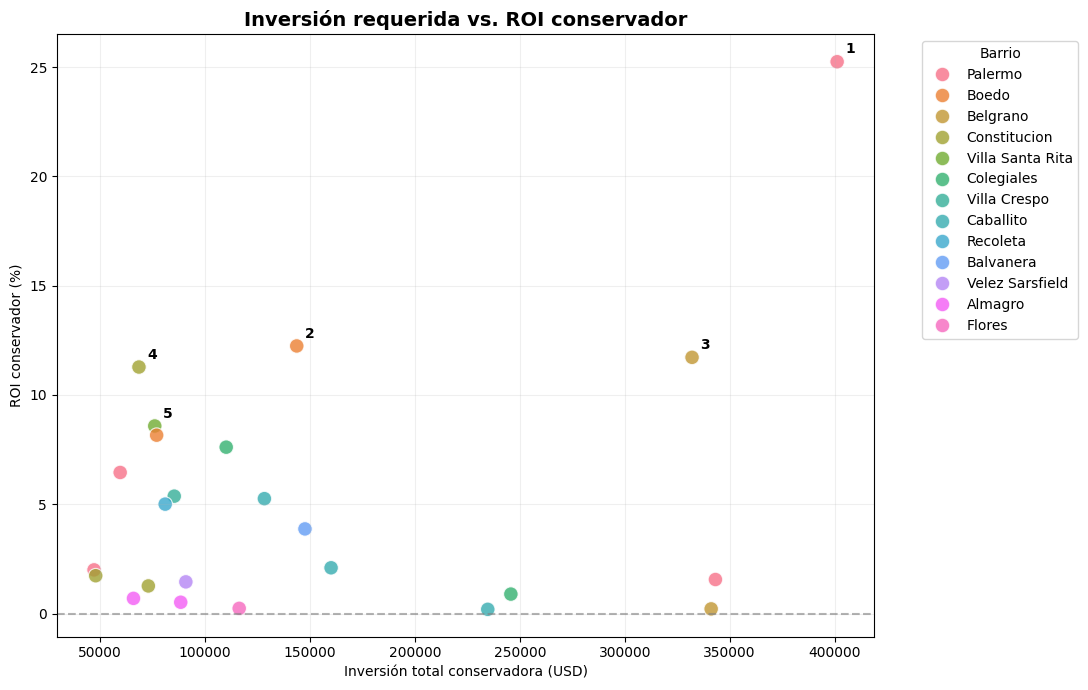

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_prioritarias,
    x="Inversion_Total_Conservador_USD",
    y="ROI_Conservador_pct",
    hue="Barrio_Oficial",
    s=110,
    alpha=0.8
)

# Destacar las primeras 5 propiedades del ranking
top_5 = df_prioritarias.nsmallest(
    5, "Ranking_Priorizado"
)

for _, fila in top_5.iterrows():
    plt.annotate(
        str(fila["Ranking_Priorizado"]),
        (
            fila["Inversion_Total_Conservador_USD"],
            fila["ROI_Conservador_pct"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Inversión requerida vs. ROI conservador",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Inversión total conservadora (USD)")
plt.ylabel("ROI conservador (%)")

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)

plt.legend(
    title="Barrio",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



### Interpretación: inversión requerida y rentabilidad conservadora

El gráfico muestra una distribución heterogénea de las 24 oportunidades prioritarias. No se observa una relación lineal clara entre la inversión total requerida y el ROI conservador.

**Propiedades destacadas**

- **Palermo (ID 612831, ranking 1):** presenta el mayor ROI conservador (25,24%), pero requiere una inversión elevada, cercana a USD 400.000 en el escenario conservador.
- **Boedo (ID 641943, ranking 2):** combina un ROI conservador de 12,24% con una inversión aproximada de USD 143.000.
- **Constitución (ID 580233, ranking 4):** presenta un ROI conservador de 11,28% con una inversión cercana a USD 68.000, destacándose por su menor requerimiento de capital.
- **Villa Santa Rita (ID 518133, ranking 5):** ofrece un ROI conservador de 8,58% con una inversión cercana a USD 76.000.

**Comparación de oportunidades**

La propiedad de Palermo lidera en rentabilidad porcentual conservadora, pero también exige el mayor capital entre las oportunidades representadas.

En cambio, Constitución y Villa Santa Rita ofrecen alternativas con menor inversión inicial y rentabilidades conservadoras relativamente elevadas.

También se identifican propiedades con inversiones superiores a USD 200.000 cuyos ROI conservadores son cercanos a cero, lo que evidencia que un mayor capital invertido no garantiza una mayor rentabilidad porcentual.

### Implicancias para la decisión de inversión

Los resultados sugieren que la selección de oportunidades debería considerar conjuntamente la rentabilidad esperada y el capital requerido.

Para inversores con capital limitado, propiedades como las identificadas en Constitución y Villa Santa Rita podrían merecer una evaluación inicial prioritaria.

Para inversores con mayor capacidad de inversión, la propiedad de Palermo podría resultar atractiva por su rentabilidad estimada, aunque presenta una exposición económica absoluta considerablemente mayor.

Estas comparaciones no reemplazan la evaluación del riesgo de obra, la liquidez del inmueble y la confiabilidad del precio de reventa estimado.



## 4. Priorización según capital requerido y rentabilidad

El ranking original identifica oportunidades a partir de los criterios económicos y de calidad definidos en la notebook 07.

En esta sección se incorpora una comparación complementaria entre la inversión total conservadora y el ROI conservador.

El objetivo es identificar propiedades que ofrecen una rentabilidad relativamente elevada con una menor necesidad de capital.

Para ello se utiliza el concepto de **dominancia**: una propiedad domina a otra cuando requiere una inversión igual o menor y ofrece un ROI conservador igual o mayor, con al menos una ventaja estricta.

Las propiedades no dominadas forman una frontera de alternativas eficientes dentro de las 24 oportunidades prioritarias.

Este análisis no reemplaza el ranking original ni incorpora riesgos adicionales; permite comparar alternativas según dos criterios económicos.


In [7]:

import numpy as np
import pandas as pd

# Trabajar con las 24 oportunidades prioritarias
df_eficiencia = df_prioritarias.copy()

capital = df_eficiencia[
    "Inversion_Total_Conservador_USD"
].to_numpy()

roi = df_eficiencia[
    "ROI_Conservador_pct"
].to_numpy()

# Identificar propiedades dominadas
dominada = np.zeros(len(df_eficiencia), dtype=bool)

for i in range(len(df_eficiencia)):
    dominada[i] = np.any(
        (capital <= capital[i]) &
        (roi >= roi[i]) &
        (
            (capital < capital[i]) |
            (roi > roi[i])
        )
    )

df_eficiencia["Dominada"] = dominada

# Propiedades no dominadas
df_frontera = (
    df_eficiencia[~df_eficiencia["Dominada"]]
    .sort_values("Inversion_Total_Conservador_USD")
    .copy()
)

print("Propiedades prioritarias:", len(df_eficiencia))
print("Propiedades no dominadas:", len(df_frontera))
print("Propiedades dominadas:", dominada.sum())

columnas_frontera = [
    "Ranking_Priorizado",
    "ID",
    "Barrio_Oficial",
    "Precio_Valor",
    "Inversion_Total_Conservador_USD",
    "ROI_Conservador_pct",
    "ROI_Base_pct",
    "PER_N_Comparables",
    "Link"
]

display(
    df_frontera[columnas_frontera]
    .round(2)
    .reset_index(drop=True)
)


Propiedades prioritarias: 24
Propiedades no dominadas: 5
Propiedades dominadas: 19


,Ranking_Priorizado,ID,Barrio_Oficial,Precio_Valor,Inversion_Total_Conservador_USD,ROI_Conservador_pct,ROI_Base_pct,PER_N_Comparables,Link
0,14,640160,Palermo,35000.0,47175.48,2.00,19.54,16.0,https://www.remax.com.ar/listings/monoambiente...
1,8,604042,Palermo,45000.0,59623.81,6.46,31.37,10.0,https://www.remax.com.ar/listings/venta-monoam...
2,4,580233,Constitucion,39500.0,68565.00,11.28,48.75,24.0,https://www.remax.com.ar/listings/3-ambientes-...
3,2,641943,Boedo,95000.0,143738.10,12.24,31.96,14.0,https://www.remax.com.ar/listings/venta-tres-a...
4,1,612831,Palermo,310000.0,401218.57,25.24,46.69,11.0,https://www.remax.com.ar/listings/duplex-piso-...



### Interpretación de la frontera eficiente

De las 24 propiedades prioritarias, **5 se encuentran en la frontera eficiente** y las otras 19 están dominadas por al menos una alternativa que ofrece igual o mayor rentabilidad conservadora con igual o menor inversión.

Las cinco propiedades representan diferentes combinaciones de capital requerido y rentabilidad estimada.

**Alternativas de menor capital**

- **Palermo (ID 640160):** requiere USD 47.175 y ofrece un ROI conservador de 2,00%. Es la alternativa de menor inversión dentro de las 24 propiedades prioritarias.
- **Palermo (ID 604042):** requiere USD 59.624 y ofrece un ROI conservador de 6,46%, mejorando la rentabilidad a cambio de una inversión mayor.
- **Constitución (ID 580233):** requiere USD 68.565 y ofrece un ROI conservador de 11,28%. Se destaca por combinar una inversión relativamente accesible con una rentabilidad conservadora de dos dígitos.

**Alternativas de mayor capital**

- **Boedo (ID 641943):** requiere USD 143.738 y presenta un ROI conservador de 12,24%.
- **Palermo (ID 612831):** requiere USD 401.219 y alcanza el mayor ROI conservador, de 25,24%.

### Implicancias para la decisión de inversión

La frontera eficiente permite reducir las 24 propiedades prioritarias a 5 alternativas que ofrecen distintas combinaciones de inversión y rentabilidad.

La propiedad de Constitución aparece como una candidata destacada para un inversor con capital más limitado, mientras que la propiedad de Palermo (ID 612831) presenta la mayor rentabilidad porcentual, pero requiere una inversión considerablemente superior.

No obstante, **pertenecer a la frontera eficiente no garantiza que una propiedad sea una buena inversión**. El análisis considera únicamente inversión y ROI conservador, sin incorporar diferencias en riesgo de obra, liquidez, ubicación específica o incertidumbre del PER.

Por lo tanto, estas cinco propiedades deberían considerarse candidatas para una evaluación individual, y no recomendaciones definitivas de compra.



### Visualización de la frontera eficiente

Se representan las 24 propiedades prioritarias según su inversión total conservadora y su ROI conservador.

Las propiedades no dominadas se destacan para visualizar las distintas alternativas eficientes según el capital requerido.

La frontera permite observar cómo aumenta la rentabilidad conservadora máxima alcanzable a medida que se consideran inversiones mayores.

Este análisis complementa el ranking original, pero no reemplaza la evaluación individual de riesgos.


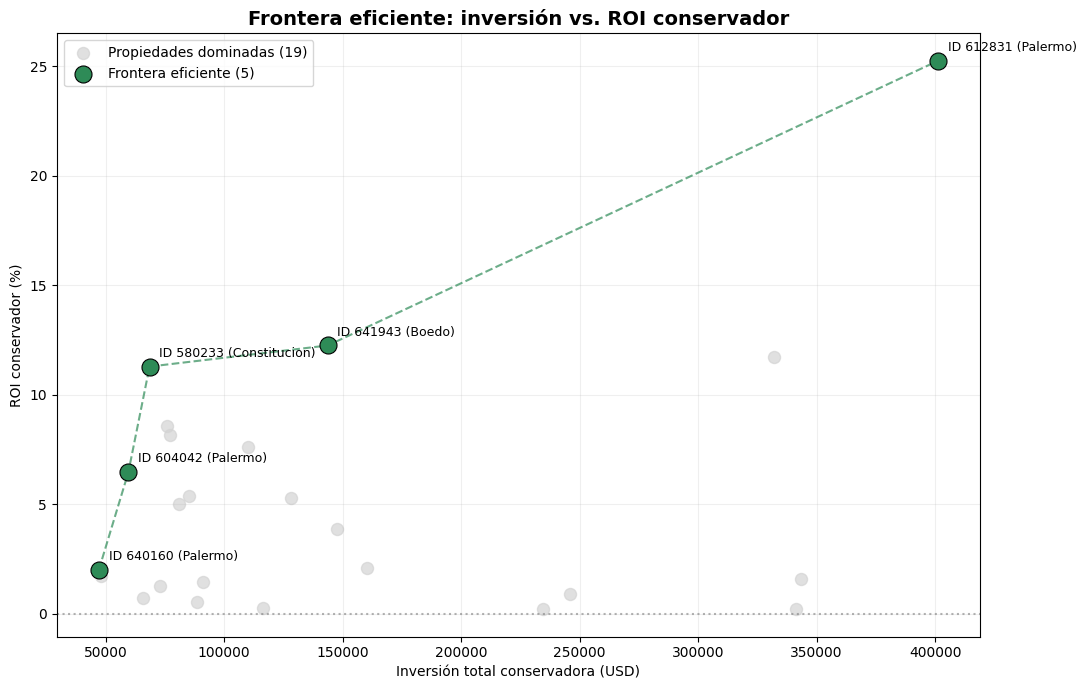

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

# Propiedades dominadas
df_dominadas = df_eficiencia[
    df_eficiencia["Dominada"]
]

plt.scatter(
    df_dominadas["Inversion_Total_Conservador_USD"],
    df_dominadas["ROI_Conservador_pct"],
    color="lightgray",
    s=75,
    alpha=0.7,
    label="Propiedades dominadas (19)"
)

# Propiedades eficientes
plt.scatter(
    df_frontera["Inversion_Total_Conservador_USD"],
    df_frontera["ROI_Conservador_pct"],
    color="seagreen",
    s=150,
    edgecolor="black",
    linewidth=0.8,
    zorder=3,
    label="Frontera eficiente (5)"
)

# Unir los puntos eficientes
plt.plot(
    df_frontera["Inversion_Total_Conservador_USD"],
    df_frontera["ROI_Conservador_pct"],
    color="seagreen",
    linestyle="--",
    alpha=0.7
)

# Etiquetar las 5 propiedades eficientes
for _, fila in df_frontera.iterrows():
    plt.annotate(
        f"ID {fila['ID']} ({fila['Barrio_Oficial']})",
        (
            fila["Inversion_Total_Conservador_USD"],
            fila["ROI_Conservador_pct"]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9
    )

plt.title(
    "Frontera eficiente: inversión vs. ROI conservador",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Inversión total conservadora (USD)")
plt.ylabel("ROI conservador (%)")

plt.axhline(0, color="gray", linestyle=":", alpha=0.6)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()



### Interpretación de la frontera eficiente

El gráfico permite visualizar las 24 propiedades prioritarias y distinguir las 5 alternativas no dominadas según inversión requerida y ROI conservador.

Se observa que las propiedades eficientes presentan diferentes combinaciones de capital y rentabilidad.

**Principales hallazgos**

- **Palermo (ID 640160):** representa la alternativa de menor inversión, con USD 47.175 y un ROI conservador de 2,00%.
- **Palermo (ID 604042):** mejora la rentabilidad hasta 6,46%, con una inversión de USD 59.624.
- **Constitución (ID 580233):** alcanza un ROI conservador de 11,28% con una inversión de USD 68.565, destacándose por su combinación de rentabilidad y capital requerido.
- **Boedo (ID 641943):** ofrece un ROI conservador de 12,24%, pero requiere USD 143.738, más del doble de la inversión necesaria en Constitución.
- **Palermo (ID 612831):** presenta la mayor rentabilidad conservadora (25,24%), aunque exige una inversión de USD 401.219.

La comparación entre Constitución y Boedo resulta especialmente relevante: para aumentar el ROI conservador de 11,28% a 12,24%, la inversión requerida aumenta aproximadamente USD 75.173.

Esto muestra que una mejora relativamente pequeña en la rentabilidad porcentual puede requerir un incremento considerable del capital invertido.

### Conclusión

La frontera eficiente permite identificar alternativas para diferentes niveles de capital disponible.

La propiedad de Constitución aparece como una candidata destacada para una revisión inicial, debido a su combinación de inversión relativamente baja y rentabilidad conservadora.

Sin embargo, este resultado no implica que sea la mejor inversión en términos absolutos, ya que la frontera no considera factores como liquidez, incertidumbre del precio de reventa, estado real del inmueble o riesgos de ejecución de la obra.

Por lo tanto, la frontera debe utilizarse como una herramienta complementaria de priorización y no como un criterio definitivo de compra.



## 5. Evaluación del margen de seguridad

En esta sección se profundiza el análisis de las cinco propiedades identificadas en la frontera eficiente.

El objetivo es comparar su margen de rentabilidad y la información disponible para estimar el precio esperado de reventa (PER).

Se consideran tres indicadores:

- **ROI conservador:** representa la rentabilidad estimada bajo el escenario económico más exigente del modelo.
- **Margen de seguridad económico:** se aproxima mediante el ROI conservador. Un valor cercano a cero indica menor capacidad para absorber desviaciones desfavorables.
- **Cantidad de comparables del PER:** permite conocer cuántas propiedades respaldan la estimación del precio de referencia. Una mayor cantidad aporta información, aunque no garantiza por sí sola una estimación más precisa.

También se incorpora el nivel de estimación del PER para evaluar si el benchmark proviene de comparables más específicos o de agrupaciones más amplias.

Este análisis busca orientar la revisión de riesgos, sin modificar el ranking original ni construir un indicador compuesto arbitrario.


In [9]:

# Evaluar margen de seguridad de la frontera eficiente
df_seguridad = df_frontera.copy()

columnas_seguridad = [
    "Ranking_Priorizado",
    "ID",
    "Barrio_Oficial",
    "Inversion_Total_Conservador_USD",
    "ROI_Conservador_pct",
    "ROI_Base_pct",
    "ROI_Optimista_pct",
    "PER_N_Comparables",
    "PER_Nivel",
    "Cantidad_Alertas"
]

tabla_seguridad = df_seguridad[
    columnas_seguridad
].copy()

# Diferencia entre el escenario base y el conservador
tabla_seguridad["Diferencia_ROI_Base_Conservador_pp"] = (
    tabla_seguridad["ROI_Base_pct"]
    - tabla_seguridad["ROI_Conservador_pct"]
)

display(
    tabla_seguridad.round(2).reset_index(drop=True)
)


,Ranking_Priorizado,ID,Barrio_Oficial,Inversion_Total_Conservador_USD,ROI_Conservador_pct,ROI_Base_pct,ROI_Optimista_pct,PER_N_Comparables,PER_Nivel,Cantidad_Alertas,Diferencia_ROI_Base_Conservador_pp
0,14,640160,Palermo,47175.48,2.00,19.54,36.19,16.0,2.0,0,17.54
1,8,604042,Palermo,59623.81,6.46,31.37,55.02,10.0,1.0,0,24.91
2,4,580233,Constitucion,68565.00,11.28,48.75,102.20,24.0,3.0,0,37.47
3,2,641943,Boedo,143738.10,12.24,31.96,53.86,14.0,3.0,0,19.71
4,1,612831,Palermo,401218.57,25.24,46.69,77.11,11.0,1.0,0,21.45



### Interpretación del margen de seguridad

El análisis de las cinco propiedades eficientes permite identificar diferencias en rentabilidad conservadora, amplitud entre escenarios y respaldo de los precios de referencia.

**1. Palermo — ID 640160**

Presenta la menor inversión conservadora (USD 47.175), pero también el menor ROI conservador (2,00%). Aunque cuenta con 16 comparables y un PER de nivel 2, su margen económico es reducido. Pequeñas desviaciones desfavorables podrían eliminar la rentabilidad.

**2. Palermo — ID 604042**

Requiere USD 59.624 y presenta un ROI conservador de 6,46%. Cuenta con 10 comparables y un PER de nivel 1. Ofrece una alternativa de menor capital con una estimación basada en comparables relativamente específicos, aunque su rentabilidad sigue siendo sensible a los supuestos.

**3. Constitución — ID 580233**

Presenta una inversión conservadora de USD 68.565 y un ROI conservador de 11,28%. Cuenta con 24 comparables, la mayor cantidad entre las cinco propiedades, pero utiliza un PER de nivel 3.

La diferencia de 37,47 puntos porcentuales entre el ROI base y el conservador es la mayor del grupo, lo que refleja una variación importante entre escenarios.

Por lo tanto, se destaca por su combinación de inversión y rentabilidad, aunque requiere especial atención a la estimación del precio de reventa.

**4. Boedo — ID 641943**

Requiere USD 143.738 y presenta un ROI conservador de 12,24%. Cuenta con 14 comparables y un PER de nivel 3.

Su diferencia entre el ROI base y el conservador es de 19,71 puntos porcentuales, menor que la observada en Constitución. Sin embargo, necesita más del doble de capital.

**5. Palermo — ID 612831**

Presenta el mayor ROI conservador (25,24%) y un ROI base de 46,69%, con una inversión conservadora de USD 401.219.

Cuenta con 11 comparables y un PER de nivel 1. Aunque ofrece la mayor rentabilidad porcentual estimada, también representa la mayor exposición de capital.

### Conclusión

El análisis permite distinguir tres perfiles de oportunidades:

- **Menor capital requerido:** Palermo (ID 640160 y 604042).
- **Equilibrio entre inversión y rentabilidad:** Constitución (ID 580233).
- **Mayor rentabilidad conservadora:** Palermo (ID 612831).

La propiedad de Constitución aparece como una candidata relevante para continuar investigando, aunque su PER de nivel 3 y la amplitud entre escenarios requieren una validación adicional.

Ninguna de las cinco propiedades presenta alertas según los controles definidos en el modelo. Sin embargo, la ausencia de alertas automáticas no elimina los riesgos de inversión.

En consecuencia, estas propiedades deben considerarse oportunidades de preselección sujetas a verificación comercial, técnica y económica.



## 6. Recomendaciones para la toma de decisiones

A partir del análisis de las 24 propiedades prioritarias y de las cinco alternativas identificadas en la frontera eficiente, se proponen recomendaciones para orientar la evaluación de oportunidades de flipping en CABA.

### 6.1. Propiedades recomendadas para revisión inicial

**Primera candidata: Constitución — ID 580233**

- Precio publicado: USD 39.500.
- Inversión total conservadora: USD 68.565.
- ROI conservador: 11,28%.
- ROI base: 48,75%.
- PER: 24 comparables, nivel 3.

Se destaca por combinar una inversión relativamente baja con una rentabilidad conservadora de dos dígitos.

Se recomienda priorizar su revisión comercial y técnica, especialmente para validar el precio esperado de reventa y el presupuesto de refacción.

**Segunda candidata: Palermo — ID 604042**

- Precio publicado: USD 45.000.
- Inversión total conservadora: USD 59.624.
- ROI conservador: 6,46%.
- ROI base: 31,37%.
- PER: 10 comparables, nivel 1.

Representa una alternativa de menor capital requerido y utiliza una referencia de mercado basada en comparables más específicos.

Se recomienda evaluar su estado real y verificar que los costos de obra no eliminen el margen económico.

**Tercera candidata: Boedo — ID 641943**

- Precio publicado: USD 95.000.
- Inversión total conservadora: USD 143.738.
- ROI conservador: 12,24%.
- ROI base: 31,96%.
- PER: 14 comparables, nivel 3.

Ofrece una rentabilidad conservadora ligeramente superior a Constitución, aunque requiere más del doble de capital.

Se recomienda considerarla como alternativa para inversores con mayor disponibilidad de fondos.

**Alternativa de mayor capital: Palermo — ID 612831**

- Precio publicado: USD 310.000.
- Inversión total conservadora: USD 401.219.
- ROI conservador: 25,24%.
- ROI base: 46,69%.
- PER: 11 comparables, nivel 1.

Presenta la mayor rentabilidad conservadora entre las propiedades prioritarias, pero requiere una inversión considerablemente superior.

Se recomienda una evaluación técnica y financiera especialmente detallada debido al capital comprometido.

### 6.2. Verificaciones previas a una decisión de compra

Antes de avanzar con una operación se recomienda:

1. **Verificar el precio de compra:** confirmar disponibilidad, condiciones de negociación y precio efectivo de cierre.
2. **Inspeccionar el inmueble:** evaluar instalaciones, estructura, humedad y alcance real de la refacción.
3. **Presupuestar la obra:** obtener cotizaciones actualizadas y contemplar imprevistos.
4. **Validar el precio de reventa:** revisar comparables recientes y estimar un precio de cierre realista.
5. **Evaluar los tiempos de operación:** considerar duración de la obra, comercialización y gastos de mantenimiento.
6. **Recalcular la rentabilidad:** actualizar el modelo con información verificada antes de comprometer capital.

### 6.3. Criterio de decisión

Se recomienda utilizar el ranking y la frontera eficiente como herramientas de preselección.

Una propiedad debería avanzar a una evaluación de inversión más detallada únicamente cuando:

- El precio publicado y las condiciones de compra estén confirmados.
- El presupuesto de refacción sea técnicamente viable.
- El precio esperado de reventa esté respaldado por comparables adecuados.
- La rentabilidad siga siendo atractiva bajo supuestos desfavorables.
- Los riesgos identificados sean compatibles con el capital y los objetivos del inversor.

Estas recomendaciones no constituyen decisiones definitivas de compra, sino un proceso de evaluación basado en evidencia.



## 7. Conclusiones generales

El análisis permitió transformar los datos inmobiliarios de CABA en un proceso de identificación, evaluación y priorización de oportunidades potenciales de flipping.

### Principales resultados

A partir del modelo económico desarrollado en la notebook 07 y de las hipótesis evaluadas en la notebook 08, se obtuvieron los siguientes resultados:

- **428 propiedades evaluadas:** inmuebles identificados como candidatos a refacción y analizados mediante escenarios económicos.
- **46 oportunidades rentables:** propiedades con ROI positivo en los tres escenarios considerados.
- **24 propiedades prioritarias:** oportunidades rentables que no presentan las alertas definidas en el modelo.
- **5 propiedades no dominadas:** alternativas que integran la frontera eficiente según inversión total conservadora y ROI conservador.

Esta reducción permite concentrar la evaluación en un conjunto más pequeño de inmuebles, manteniendo criterios de selección explícitos y reproducibles.

### Hallazgos principales

Las oportunidades identificadas presentan diferencias importantes en inversión requerida, rentabilidad estimada y características del mercado de referencia.

La propiedad de **Constitución (ID 580233)** se destaca por combinar una inversión conservadora de USD 68.565 con un ROI conservador de 11,28%, aunque requiere validar su precio de reventa estimado mediante un PER de nivel 3.

La propiedad de **Palermo (ID 604042)** representa una alternativa de menor inversión, mientras que **Boedo (ID 641943)** ofrece una rentabilidad conservadora ligeramente superior a Constitución, pero exige más del doble de capital.

Por su parte, **Palermo (ID 612831)** presenta el mayor ROI conservador de las propiedades prioritarias (25,24%), aunque requiere una inversión aproximada de USD 401.219.

### Limitaciones del análisis

Los resultados dependen de precios publicados, estimaciones del PER y supuestos de costos de refacción, mantenimiento y comercialización.

Además, el análisis de sensibilidad realizado en la notebook 08 mostró que muchas oportunidades dejan de ser rentables ante cambios desfavorables en los costos o en el precio de reventa.

Por lo tanto, la rentabilidad estimada no debe interpretarse como una ganancia garantizada.

### Conclusión final

El proyecto demuestra que es posible utilizar herramientas de analítica descriptiva para identificar propiedades potencialmente subvaluadas y evaluar su atractivo económico.

La combinación del PER, el modelo de escenarios, el ranking priorizado y la frontera eficiente permite transformar un conjunto amplio de publicaciones inmobiliarias en una selección de oportunidades para investigación.

El principal aporte del análisis no consiste en determinar qué propiedad comprar, sino en **reducir el universo de búsqueda y orientar las decisiones hacia inmuebles que justifican una evaluación comercial, técnica y financiera más detallada**.
